<a href="https://colab.research.google.com/github/iqbaal24/ML2026/blob/main/JS13_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS13 - Artificial Neural Network (ANN) dan Evaluasi Classifier
Notebook ini menggabungkan **Praktikum 1, 2, 3 dan Tugas Praktikum (MNIST)** dalam satu file. Setiap bagian berisi penjelasan, kode, dan pengerjaan tugasnya.

Isi notebook: Praktikum 1 (JST manual dengan backpropagation, XOR), Praktikum 2 (Keras, klasifikasi Iris), Praktikum 3 (Keras, regresi harga rumah), dan Tugas Praktikum (MNIST).

Catatan: jalankan sel dari atas ke bawah. Sangat disarankan memakai Google Colab karena TensorFlow sudah terpasang.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


---
# Praktikum 1 - JST Manual: Forward Pass dan Backpropagation

**Konsep singkat.** Jaringan saraf tiruan (JST) belajar dengan cara memperbaiki kesalahannya berulang kali. Caranya ada empat tahap: (1) *forward pass*, data masuk dari input ke output untuk menghasilkan prediksi; (2) hitung error, yaitu selisih prediksi dengan target; (3) *backward pass* (backpropagation), error dikirim mundur dari output ke input untuk mengetahui seberapa besar tiap bobot ikut menyebabkan error; (4) update bobot dengan gradient descent supaya error di putaran berikutnya lebih kecil.

**Dataset.** Kita memakai XOR. XOR bernilai 1 jika kedua input berbeda. Data ini tidak bisa dipisahkan oleh satu garis lurus, jadi butuh hidden layer.

In [2]:
# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])
print("X:\n", X)
print("y:\n", y)

X:
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]
y:
 [[0]
 [1]
 [1]
 [0]]


**Fungsi aktivasi.** Sigmoid mengubah angka apa pun menjadi nilai antara 0 dan 1. Turunannya dipakai saat backpropagation. Perhatikan bahwa `sigmoid_derivative(x)` menerima nilai yang *sudah* melewati sigmoid, sehingga rumusnya `x * (1 - x)`.

In [3]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

**Kode asli modul.** Parameter: 2 input, 2 neuron hidden, 1 output, learning rate 0.1. Bobot diisi acak (`randn`) dan bias diisi nol. Training berjalan 10.000 epoch dan loss dicetak tiap 1000 epoch.

In [4]:
# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Training
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss}")

# Output akhir
print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.3172265364816893
Epoch 1000, Loss: 0.24977090920991038
Epoch 2000, Loss: 0.2449941753889262
Epoch 3000, Loss: 0.220334860028847
Epoch 4000, Loss: 0.19354365894781006
Epoch 5000, Loss: 0.18231015105929457
Epoch 6000, Loss: 0.17725004354194318
Epoch 7000, Loss: 0.17451313710700062
Epoch 8000, Loss: 0.17283309624522647
Epoch 9000, Loss: 0.17170943074052863
Prediksi:
[[0.07321002]
 [0.66115541]
 [0.66120303]
 [0.66984093]]


**Cara membaca hasil.** Loss (MSE) seharusnya turun dari waktu ke waktu. Prediksi akhir yang bagus mendekati `[0, 1, 1, 0]`. Karena bobot awal acak, hasil tiap menjalankan bisa berbeda. Dengan hanya 2 neuron hidden, kadang XOR belum terpelajari dengan sempurna.

## Tugas 1
Tiga hal yang diminta: (a) ubah hidden layer menjadi 3 neuron, (b) bandingkan loss dengan konfigurasi awal, (c) tambahkan ReLU dan bandingkan.

Agar adil, kita bungkus kode di atas menjadi satu fungsi `train_xor` dan memakai **seed yang sama** untuk semua percobaan. Untuk ReLU, hidden layer memakai ReLU sedangkan output layer tetap sigmoid (karena output XOR di rentang 0-1).

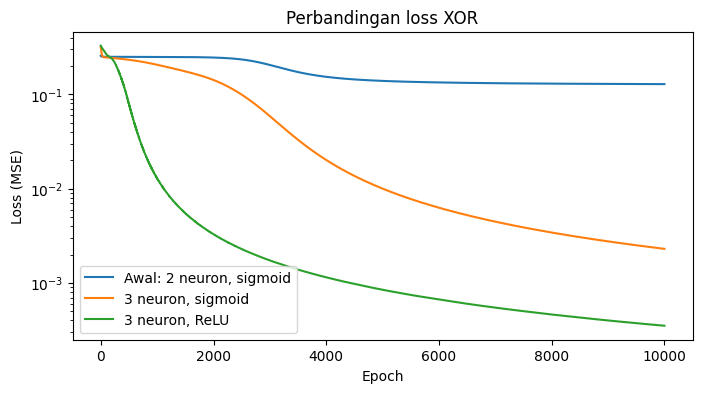

,Konfigurasi,Loss akhir,Prediksi
0,"Awal: 2 neuron, sigmoid",0.128227,"[0.053, 0.496, 0.951, 0.503]"
1,"3 neuron, sigmoid",0.002297,"[0.025, 0.953, 0.951, 0.063]"
2,"3 neuron, ReLU",0.000352,"[0.03, 0.986, 0.986, 0.012]"


In [5]:
def relu(x):
    return np.maximum(0, x)

def relu_derivative(a):
    # a adalah output relu; nilainya > 0 berarti turunannya 1, selain itu 0
    return (a > 0).astype(float)

def train_xor(hidden_size=2, activation='sigmoid', lr=0.1, epochs=10000, seed=42):
    rng = np.random.RandomState(seed)
    W1 = rng.randn(2, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = rng.randn(hidden_size, 1)
    b2 = np.zeros((1, 1))

    if activation == 'sigmoid':
        act, act_d = sigmoid, sigmoid_derivative
    else:
        act, act_d = relu, relu_derivative

    losses = []
    for epoch in range(epochs):
        a1 = act(X @ W1 + b1)
        a2 = sigmoid(a1 @ W2 + b2)
        error = y - a2

        d_a2 = error * sigmoid_derivative(a2)
        d_a1 = (d_a2 @ W2.T) * act_d(a1)

        W2 += lr * (a1.T @ d_a2)
        b2 += lr * d_a2.sum(axis=0, keepdims=True)
        W1 += lr * (X.T @ d_a1)
        b1 += lr * d_a1.sum(axis=0, keepdims=True)

        losses.append(np.mean(np.square(error)))
    return losses, a2

configs = [
    ("Awal: 2 neuron, sigmoid", dict(hidden_size=2, activation='sigmoid')),
    ("3 neuron, sigmoid",       dict(hidden_size=3, activation='sigmoid')),
    ("3 neuron, ReLU",          dict(hidden_size=3, activation='relu')),
]

hasil_xor = []
plt.figure(figsize=(8,4))
for nama, cfg in configs:
    losses, pred = train_xor(**cfg)
    plt.plot(losses, label=nama)
    hasil_xor.append({"Konfigurasi": nama, "Loss akhir": losses[-1],
                      "Prediksi": np.round(pred.ravel(), 3)})
plt.xlabel("Epoch"); plt.ylabel("Loss (MSE)"); plt.yscale("log")
plt.title("Perbandingan loss XOR"); plt.legend(); plt.show()

pd.DataFrame(hasil_xor)

**Analisis Tugas 1.** Biasanya hidden layer dengan 3 neuron mencapai loss yang lebih kecil daripada 2 neuron, karena kapasitas jaringan lebih besar. ReLU sering menurunkan loss lebih cepat, tetapi pada jaringan sekecil ini ReLU bisa "mati" (neuron selalu bernilai 0) sehingga hasilnya sangat bergantung pada bobot awal. Lihat grafik dan tabel di atas, lalu tulis kesimpulan dari hasil yang kamu dapat di sel berikut.

*Kesimpulan saya (isi sendiri setelah menjalankan):* ...

---
# Praktikum 2 - Keras: Klasifikasi Data Iris

**Konsep singkat.** Keras adalah API tingkat tinggi untuk membangun JST dengan mudah, sedangkan TensorFlow adalah *framework* yang menjalankannya di belakang. Langkah kerjanya: import library, load dataset, bangun model, kompilasi dan latih, lalu evaluasi.

**Dataset Iris** berisi 150 bunga, 4 fitur (panjang dan lebar sepal dan petal), dan 3 kelas. Label diubah ke *one-hot encoding* (misalnya kelas 1 menjadi `[0,1,0]`) karena output model memakai 3 neuron softmax dan loss `categorical_crossentropy`.

Catatan versi: modul memakai `OneHotEncoder(sparse=False)` dan `input_shape` di dalam `Dense`. Pada library versi baru, `sparse` diganti `sparse_output` dan input sebaiknya ditulis dengan `tf.keras.Input`. Fungsinya sama persis.

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

tf.random.set_seed(42)
np.random.seed(42)

# Load dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target.reshape(-1, 1)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y_iris = encoder.fit_transform(y_iris)

# Split data
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_iris, y_iris, test_size=0.2, random_state=42)
print(Xi_train.shape, Xi_test.shape)

(120, 4) (30, 4)


**Membangun dan melatih model (konfigurasi awal).** Dua hidden layer (10 dan 8 neuron, ReLU) dan output 3 neuron softmax. Optimizer `adam`, 50 epoch, batch size 8.

In [7]:
model_iris = tf.keras.Sequential([
    tf.keras.Input(shape=(4,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model_iris.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_iris.fit(Xi_train, yi_train, epochs=50, batch_size=8, verbose=0)

loss, acc = model_iris.evaluate(Xi_test, yi_test, verbose=0)
print(f"Loss: {loss:.4f}")
print(f"Akurasi: {acc}")

Loss: 0.2380
Akurasi: 0.9333333373069763


## Tugas 2 dan Tugas 3
Tugas 2: ubah jumlah neuron hidden layer lalu bandingkan akurasi dengan konfigurasi awal. Tugas 3: bandingkan Sigmoid dan ReLU pada Iris, catat perbedaan loss dan akurasi.

Kita buat fungsi `latih_iris` agar semua percobaan memakai cara yang sama, lalu hasilnya dirangkum dalam satu tabel.

In [8]:
def latih_iris(neurons=(10, 8), activation='relu', epochs=50):
    tf.keras.utils.set_random_seed(42)
    layers = [tf.keras.Input(shape=(4,))]
    for n in neurons:
        layers.append(tf.keras.layers.Dense(n, activation=activation))
    layers.append(tf.keras.layers.Dense(3, activation='softmax'))
    m = tf.keras.Sequential(layers)
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    m.fit(Xi_train, yi_train, epochs=epochs, batch_size=8, verbose=0)
    l, a = m.evaluate(Xi_test, yi_test, verbose=0)
    return l, a

hasil = []
# Tugas 2: variasi jumlah neuron (aktivasi ReLU)
for neurons in [(10, 8), (4, 4), (32, 16), (64, 32)]:
    l, a = latih_iris(neurons, 'relu')
    hasil.append({"Tugas": "2 (neuron)", "Hidden layer": str(neurons),
                  "Aktivasi": "relu", "Loss": round(l, 4), "Akurasi": round(a, 4)})

# Tugas 3: Sigmoid vs ReLU (neuron awal 10 dan 8)
for act in ['sigmoid', 'relu']:
    l, a = latih_iris((10, 8), act)
    hasil.append({"Tugas": "3 (aktivasi)", "Hidden layer": "(10, 8)",
                  "Aktivasi": act, "Loss": round(l, 4), "Akurasi": round(a, 4)})

pd.DataFrame(hasil)

,Tugas,Hidden layer,Aktivasi,Loss,Akurasi
0,2 (neuron),"(10, 8)",relu,0.2103,0.9667
1,2 (neuron),"(4, 4)",relu,0.7143,0.7000
2,2 (neuron),"(32, 16)",relu,0.0924,1.0000
3,2 (neuron),"(64, 32)",relu,0.0921,1.0000
4,3 (aktivasi),"(10, 8)",sigmoid,0.5842,0.8000
5,3 (aktivasi),"(10, 8)",relu,0.2103,0.9667


**Analisis.** Iris adalah dataset kecil dan mudah, jadi akurasi biasanya sudah tinggi (sekitar 0,9 sampai 1,0) pada hampir semua konfigurasi. Jumlah neuron yang terlalu sedikit (misalnya 4 dan 4) bisa membuat model kurang belajar, sedangkan neuron yang banyak tidak selalu lebih baik pada data sekecil ini. Untuk aktivasi, dengan epoch yang sama ReLU umumnya mencapai loss lebih rendah daripada Sigmoid, karena gradien ReLU tidak mengecil seperti Sigmoid. Bandingkan dengan angka di tabel kamu.

*Kesimpulan saya (isi sendiri):* ...

---
# Praktikum 3 - Keras: Regresi Prediksi Harga Rumah

**Konsep singkat.** Pada regresi, outputnya angka kontinu (bukan kelas), jadi output layer hanya 1 neuron **tanpa aktivasi**, dan loss yang dipakai `mse`.

## Bagian A: Dataset dummy (luas dan harga)
Data hanya 5 baris. Fitur dan target dinormalisasi dengan `StandardScaler` supaya skalanya seragam dan training lebih stabil.

Perbaikan kecil dari kode modul: `y` harus berbentuk 2 dimensi (`data[['harga']]`) agar bisa dipakai `StandardScaler`.

In [9]:
from sklearn.preprocessing import StandardScaler

data = pd.DataFrame({
    'luas':  [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X_d = data[['luas']]
y_d = data[['harga']]

# Normalisasi
scaler_x = StandardScaler()
scaler_y = StandardScaler()
X_d = scaler_x.fit_transform(X_d)
y_d = scaler_y.fit_transform(y_d)

# Split data
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_d, y_d, test_size=0.2, random_state=42)

# Model
tf.keras.utils.set_random_seed(42)
model_d = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(1)
])
model_d.compile(optimizer='adam', loss='mse')
model_d.fit(Xd_train, yd_train, epochs=100, verbose=0)

# Evaluasi (prediksi dikembalikan ke skala harga asli)
pred_scaled = model_d.predict(Xd_test, verbose=0)
print("Prediksi (skala asli):", scaler_y.inverse_transform(pred_scaled).ravel())
print("Aktual (skala asli)  :", scaler_y.inverse_transform(yd_test).ravel())

Prediksi (skala asli): [697.72266]
Aktual (skala asli)  : [600.]


## Tugas 4
Ubah learning rate lalu bandingkan hasil loss. Learning rate adalah besar langkah update bobot. Terlalu besar bisa membuat loss naik-turun, terlalu kecil membuat belajar sangat lambat.

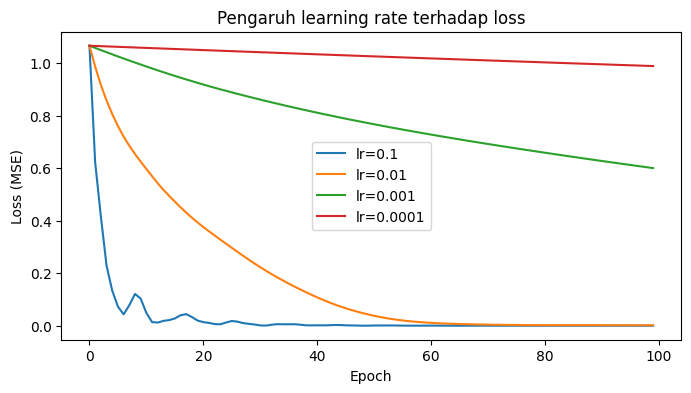

,Learning rate,Loss akhir
0,0.1000,0.000010
1,0.0100,0.001676
2,0.0010,0.600234
3,0.0001,0.988751


In [10]:
from tensorflow.keras.optimizers import Adam

plt.figure(figsize=(8,4))
ringkas = []
for lr in [0.1, 0.01, 0.001, 0.0001]:
    tf.keras.utils.set_random_seed(42)
    m = tf.keras.Sequential([
        tf.keras.Input(shape=(1,)),
        tf.keras.layers.Dense(10, activation='relu'),
        tf.keras.layers.Dense(1)
    ])
    m.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    h = m.fit(Xd_train, yd_train, epochs=100, verbose=0)
    plt.plot(h.history['loss'], label=f"lr={lr}")
    ringkas.append({"Learning rate": lr, "Loss akhir": round(h.history['loss'][-1], 6)})

plt.xlabel("Epoch"); plt.ylabel("Loss (MSE)")
plt.title("Pengaruh learning rate terhadap loss"); plt.legend(); plt.show()
pd.DataFrame(ringkas)

**Analisis Tugas 4.** Pada data sederhana ini, learning rate 0,01 sampai 0,1 biasanya menurunkan loss dengan cepat, sedangkan 0,0001 turun sangat pelan sehingga setelah 100 epoch loss masih besar. Lihat grafik untuk melihat mana yang paling cepat konvergen.

## Bagian B: Prediksi harga rumah dengan MLP
Modul memakai `load_boston`, tetapi fungsi itu **sudah dihapus** dari scikit-learn versi baru (mulai 1.2) karena masalah etika data. Sebagai gantinya kita pakai `tf.keras.datasets.boston_housing`, yaitu data Boston yang sama (13 fitur, target harga rumah) yang masih tersedia di Keras. Alur tetap sama: preprocessing, bangun model 64-32-1, training 200 epoch, plot, lalu hitung RMSE.

57026/57026 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Bentuk data: (506, 13) (506,)


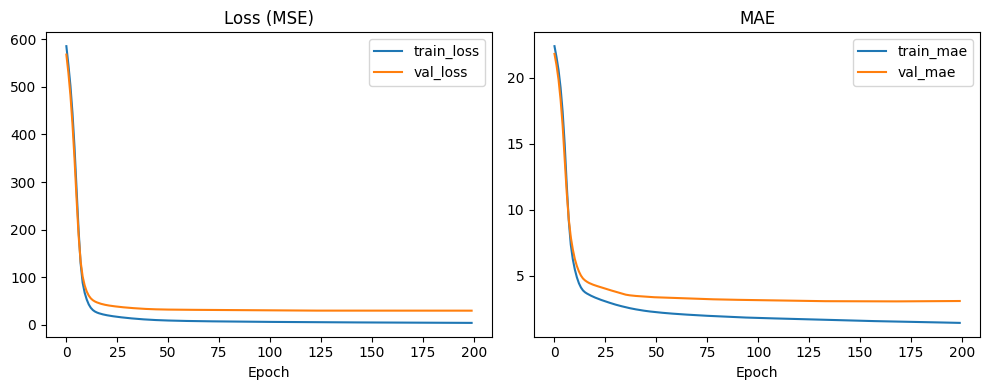

RMSE: 5.439658498631198


In [11]:
from sklearn.metrics import mean_squared_error

# 1. Load (gabungkan lalu bagi ulang 80:20 seperti di modul)
(x_tr, y_tr), (x_te, y_te) = tf.keras.datasets.boston_housing.load_data()
Xb = np.concatenate([x_tr, x_te])
yb = np.concatenate([y_tr, y_te])
print("Bentuk data:", Xb.shape, yb.shape)

# 2. Preprocess
scaler_b = StandardScaler()
Xs = scaler_b.fit_transform(Xb)
Xb_train, Xb_val, yb_train, yb_val = train_test_split(Xs, yb, test_size=0.2, random_state=42)

# 3. Build model
tf.keras.utils.set_random_seed(42)
model_b = tf.keras.Sequential([
    tf.keras.Input(shape=(Xb_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])
model_b.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model_b.fit(Xb_train, yb_train, validation_data=(Xb_val, yb_val),
                epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss')
plt.xlabel("Epoch"); plt.title("Loss (MSE)"); plt.legend()
plt.subplot(1,2,2)
plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae')
plt.xlabel("Epoch"); plt.title("MAE"); plt.legend()
plt.tight_layout(); plt.show()

pred = model_b.predict(Xb_val, verbose=0)
print('RMSE:', np.sqrt(mean_squared_error(yb_val, pred)))

**Cara membaca hasil.** Jika `train_loss` terus turun tetapi `val_loss` mulai naik, model mulai *overfitting*. RMSE menunjukkan rata-rata besar kesalahan prediksi dalam satuan target (ribuan dolar). Semakin kecil semakin baik.

---
# Tugas Praktikum - Klasifikasi Angka Tulisan Tangan (MNIST)

**Konsep singkat.** MNIST berisi 70.000 gambar angka 0-9 berukuran 28x28 piksel (60.000 latih, 10.000 uji). Langkah: load data, normalisasi piksel dari 0-255 menjadi 0-1, one-hot encoding label, bangun model dengan 2 hidden layer, kompilasi, latih, lalu evaluasi. Lapisan `Flatten` mengubah gambar 28x28 menjadi vektor 784 angka agar bisa masuk ke `Dense`.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (10000, 28, 28)


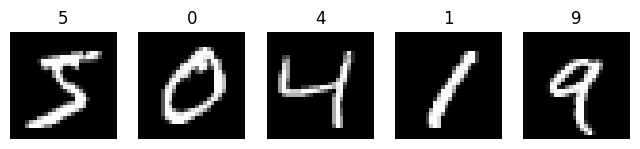

In [12]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(Xm_train, ym_train), (Xm_test, ym_test) = mnist.load_data()

# Normalisasi data (0-255 -> 0-1)
Xm_train = Xm_train / 255.0
Xm_test = Xm_test / 255.0

# One-hot encoding label
ym_train = to_categorical(ym_train, 10)
ym_test = to_categorical(ym_test, 10)

print(Xm_train.shape, Xm_test.shape)

# Lihat beberapa contoh gambar
plt.figure(figsize=(8,2))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(Xm_train[i], cmap='gray'); plt.axis('off')
    plt.title(int(np.argmax(ym_train[i])))
plt.show()

**Melengkapi bagian yang kosong di modul.** Model awal: Flatten, Dense 128 (ReLU), Dense 64 (ReLU), Dense 10 (softmax). Kompilasi memakai `adam` dan `categorical_crossentropy`. Pelatihan 10 epoch, batch size 128.

In [13]:
# 2. Bangun model JST
model = Sequential([
    tf.keras.Input(shape=(28, 28)),
    Flatten(),                       # Ubah gambar 28x28 menjadi vektor
    Dense(128, activation='relu'),   # Hidden layer 1
    Dense(64, activation='relu'),    # Hidden layer 2
    Dense(10, activation='softmax')  # Output layer (10 kelas)
])

# 3. Kompilasi model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 4. Latih model
model.fit(Xm_train, ym_train, epochs=10, batch_size=128, validation_split=0.1, verbose=1)

# 5. Evaluasi model
loss, acc = model.evaluate(Xm_test, ym_test)
print(f"Akurasi pada data uji: {acc:.4f}")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9011 - loss: 0.3479 - val_accuracy: 0.9635 - val_loss: 0.1336
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9581 - loss: 0.1421 - val_accuracy: 0.9700 - val_loss: 0.1022
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9703 - loss: 0.0998 - val_accuracy: 0.9725 - val_loss: 0.0934
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9778 - loss: 0.0748 - val_accuracy: 0.9725 - val_loss: 0.0921
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9835 - loss: 0.0576 - val_accuracy: 0.9722 - val_loss: 0.0942
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9868 - loss: 0.0455 - val_accuracy: 0.9727 - val_loss: 0.0961
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9904 - loss: 0.0358 - val_accuracy: 0.9723 - val_loss: 0.0989
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9928 - loss: 0.0285 - val_accuracy: 0

## Eksperimen parameter
Yang diminta: (a) ubah neuron hidden layer menjadi 256 dan 128, (b) tambah satu hidden layer lagi, (c) bandingkan akurasi dan waktu pelatihan, (d) bandingkan Sigmoid dan ReLU.

Semua percobaan dijalankan dengan fungsi di bawah (5 epoch agar tidak terlalu lama), waktu pelatihan diukur dengan `time`.

In [14]:
def eksperimen_mnist(nama, neurons, activation='relu', epochs=5):
    tf.keras.utils.set_random_seed(42)
    layers = [tf.keras.Input(shape=(28, 28)), Flatten()]
    for n in neurons:
        layers.append(Dense(n, activation=activation))
    layers.append(Dense(10, activation='softmax'))
    m = Sequential(layers)
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    mulai = time.time()
    m.fit(Xm_train, ym_train, epochs=epochs, batch_size=128, verbose=0)
    durasi = time.time() - mulai

    l, a = m.evaluate(Xm_test, ym_test, verbose=0)
    return {"Percobaan": nama, "Hidden layer": str(neurons), "Aktivasi": activation,
            "Loss uji": round(l, 4), "Akurasi uji": round(a, 4), "Waktu (detik)": round(durasi, 1)}

hasil_mnist = [
    eksperimen_mnist("Awal",             (128, 64)),
    eksperimen_mnist("Neuron diperbesar", (256, 128)),
    eksperimen_mnist("Tambah 1 layer",    (128, 64, 32)),
    eksperimen_mnist("Sigmoid",           (128, 64), activation='sigmoid'),
    eksperimen_mnist("ReLU",              (128, 64), activation='relu'),
]
df_mnist = pd.DataFrame(hasil_mnist)
df_mnist

,Percobaan,Hidden layer,Aktivasi,Loss uji,Akurasi uji,Waktu (detik)
0,Awal,"(128, 64)",relu,0.0887,0.9733,13.4
1,Neuron diperbesar,"(256, 128)",relu,0.0763,0.9781,22.5
2,Tambah 1 layer,"(128, 64, 32)",relu,0.0835,0.9733,15.0
3,Sigmoid,"(128, 64)",sigmoid,0.1325,0.9595,13.5
4,ReLU,"(128, 64)",relu,0.0887,0.9733,14.8


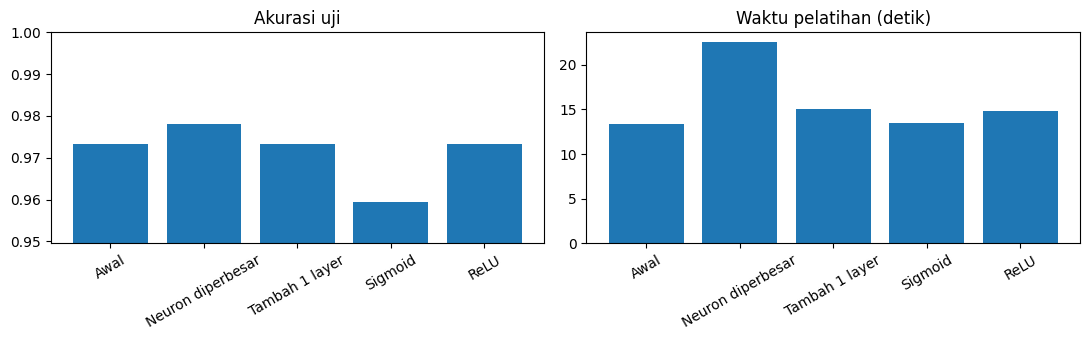

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(df_mnist["Percobaan"], df_mnist["Akurasi uji"]); ax[0].set_title("Akurasi uji")
ax[0].set_ylim(df_mnist["Akurasi uji"].min() - 0.01, 1.0)
ax[1].bar(df_mnist["Percobaan"], df_mnist["Waktu (detik)"]); ax[1].set_title("Waktu pelatihan (detik)")
for a in ax: a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

**Analisis.** Secara umum, menambah neuron atau layer sedikit menaikkan akurasi (biasanya di kisaran 97-98% pada MNIST) tetapi membuat pelatihan lebih lama karena parameter bertambah. Kenaikannya kecil, jadi model yang jauh lebih besar tidak selalu sepadan dengan tambahan waktunya. Untuk aktivasi, ReLU biasanya lebih akurat dan lebih cepat belajar daripada Sigmoid pada jaringan seperti ini. Sesuaikan dengan angka yang muncul di tabel kamu.

